In [148]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import patches
import seaborn as sns
from copy import deepcopy

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from modules.autolog import ASLT
from sklearn.preprocessing import StandardScaler,OrdinalEncoder,PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression,Lasso
from sklearn.model_selection import cross_val_score
from sklearn.cluster import DBSCAN
import optuna
from sklearn.base import clone

In [149]:
df = pd.read_csv('./abalone/abalone.data',header=None,names=['sex','length','diameter','height','whole_weight','shucked_weight','viscera_weight','shell_weight','rings'])
df['rings'] = df.pop('rings')
print(df.shape)
df.head()

(4177, 9)


,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [150]:
print('NaN values of each columns:')
print(df.isna().sum())

NaN values of each columns:
sex               0
length            0
diameter          0
height            0
whole_weight      0
shucked_weight    0
viscera_weight    0
shell_weight      0
rings             0
dtype: int64


In [151]:
print('Count of duplicated rows:')
print(df.duplicated().sum())

Count of duplicated rows:
0


In [152]:
print('Datatypes of each columns:')
print(df.dtypes)

Datatypes of each columns:
sex                object
length            float64
diameter          float64
height            float64
whole_weight      float64
shucked_weight    float64
viscera_weight    float64
shell_weight      float64
rings               int64
dtype: object


# **Preprocessing**

In [153]:
from sklearn.model_selection import train_test_split

df_train,df_test = train_test_split(df,test_size=0.2,random_state=42)
print(df_train.shape,df_test.shape)

(3341, 9) (836, 9)


### **Removing Outliers with DBSCAN**

In [154]:
pl_out = Pipeline([
    ('encoder',ColumnTransformer([
      ('cat',OrdinalEncoder(),['sex'])  
    ],remainder='passthrough')),
    ('scaler',StandardScaler()),
    ('cluster',DBSCAN(eps=1.5,min_samples=10))
])
outlier_indexs = pl_out.fit_predict(df_train)
outlier_indexs = np.where(outlier_indexs == -1, 1, 0).astype(bool)
df_train_out = df_train[~outlier_indexs]
print(f'Removed {outlier_indexs.sum()} rows detected as outliers.')

df_train_out = df_train_out.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

Removed 22 rows detected as outliers.


In [155]:
df_train_out

,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings
0,I,0.550,0.445,0.125,0.6720,0.2880,0.1365,0.210,11
1,I,0.475,0.355,0.100,0.5035,0.2535,0.0910,0.140,8
2,F,0.305,0.225,0.070,0.1485,0.0585,0.0335,0.045,7
3,I,0.275,0.200,0.065,0.1165,0.0565,0.0130,0.035,7
4,M,0.495,0.380,0.135,0.6295,0.2630,0.1425,0.215,12
...,...,...,...,...,...,...,...,...,...
3314,F,0.490,0.400,0.115,0.5690,0.2560,0.1325,0.145,9
3315,F,0.670,0.550,0.190,1.3905,0.5425,0.3035,0.400,12
3316,M,0.510,0.395,0.125,0.5805,0.2440,0.1335,0.188,11
3317,M,0.575,0.465,0.120,1.0535,0.5160,0.2185,0.235,9


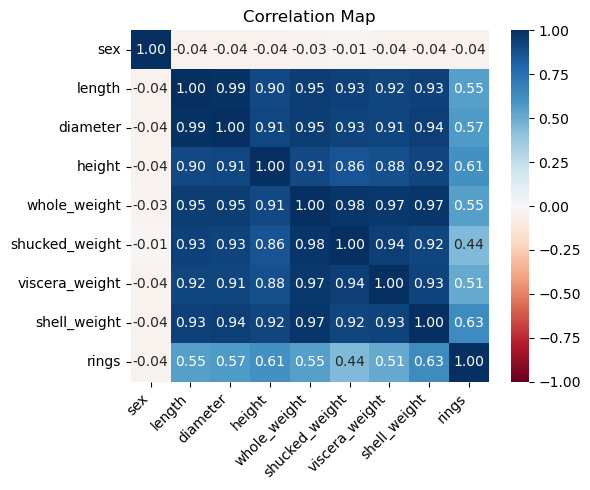

In [156]:
_df = df_train_out.copy()
_df = OrdinalEncoder().fit_transform(_df)
_df = pd.DataFrame(_df,columns=df_train_out.columns)

corr_mat = _df.corr()

plt.figure(figsize=(6,5))
sns.heatmap(corr_mat,vmin=-1,vmax=1,annot=True,fmt='.2f',cmap='RdBu')
plt.xticks(rotation=45,ha='right')
plt.title('Correlation Map')
plt.tight_layout()
plt.show()

In [157]:
# df_train_out = df_train_out.drop(['sex','shucked_weight'],axis=1)
# df_test = df_test.drop(['sex','shucked_weight'],axis=1)

### **Preprocessing Pipeline**

In [ ]:
num_cols = df_train_out.drop('rings',axis=1).select_dtypes(include='number').columns
cat_cols = df_train_out.drop('rings',axis=1).select_dtypes(exclude='number').columns
num_pl = Pipeline([
            ('aslt',ASLT(beta=10)),
            ('scaler',StandardScaler()),
            ('pca',PCA())
        ])
ct = ColumnTransformer([
    ('numeric',num_pl,num_cols),
    ('categorical',OrdinalEncoder(),cat_cols)
],remainder='passthrough')
ct

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fea

# **Modelling**

In [159]:
X_train = df_train_out.drop('rings',axis=1)
y_train = df_train_out['rings']

X_test = df_test.drop('rings',axis=1)
y_test = df_test['rings']

n_cols = X_test.shape[1]
n_cols

8

In [160]:
def objective(trial):
    pl = Pipeline([
        ('preprocess',clone(ct)),
        ('estimator',LinearRegression(positive=True))
    ])
    params = {
        'preprocess__numeric__aslt__beta': trial.suggest_float('preprocess__numeric__aslt__beta',-50,50),
        'preprocess__numeric__pca__n_components': trial.suggest_int('preprocess__numeric__pca__n_components',2,n_cols)
    }
    pl.set_params(**params)
    score = cross_val_score(pl,X_train,y_train,n_jobs=4,cv=4,scoring='neg_mean_squared_error')
    neg_mse = score.mean()
    return neg_mse

study_lr = optuna.create_study(direction='maximize')
study_lr.optimize(objective,n_trials=50)

[I 2026-11-17 11:26:39,817] A new study created in memory with name: no-name-a01c1431-ef19-4c85-a603-d2c20ced5d2f
[W 2026-11-17 11:26:41,521] Trial 0 failed with parameters: {'preprocess__numeric__aslt__beta': -35.87053728148025, 'preprocess__numeric__pca__n_components': 6} because of the following error: ValueError('\nAll the 4 fits failed.\nIt is very likely that your model is misconfigured.\nYou can try to debug the error by setting error_score=\'raise\'.\n\nBelow are more details about the failures:\n--------------------------------------------------------------------------------\n4 fits failed with the following error:\nTraceback (most recent call last):\n  File "/home/milkywayweaver/miniconda3/envs/ds-pt/lib/python3.12/site-packages/pandas/core/indexes/base.py", line 3812, in get_loc\n    return self._engine.get_loc(casted_key)\n           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^\n  File "pandas/_libs/index.pyx", line 167, in pandas._libs.index.IndexEngine.get_loc\n  File "pandas/_libs/i

ValueError: 
All the 4 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
4 fits failed with the following error:
Traceback (most recent call last):
  File "/home/milkywayweaver/miniconda3/envs/ds-pt/lib/python3.12/site-packages/pandas/core/indexes/base.py", line 3812, in get_loc
    return self._engine.get_loc(casted_key)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "pandas/_libs/index.pyx", line 167, in pandas._libs.index.IndexEngine.get_loc
  File "pandas/_libs/index.pyx", line 196, in pandas._libs.index.IndexEngine.get_loc
  File "pandas/_libs/hashtable_class_helper.pxi", line 7088, in pandas._libs.hashtable.PyObjectHashTable.get_item
  File "pandas/_libs/hashtable_class_helper.pxi", line 7096, in pandas._libs.hashtable.PyObjectHashTable.get_item
KeyError: 'rings'

The above ex

In [ ]:
def objective(trial):
    pl = Pipeline([
        ('preprocess',clone(ct)),
        ('estimator',Lasso(positive=True))
    ])
    params = {
        'preprocess__numeric__aslt__beta': trial.suggest_float('preprocess__numeric__aslt__beta',-50,50),
        'preprocess__numeric__pca__n_components': trial.suggest_int('preprocess__numeric__pca__n_components',2,n_cols),
        'estimator__alpha': trial.suggest_float('estimator__alpha',0,10),
        'estimator__selection': trial.suggest_categorical('estimator__selection',['cyclic','random'])
    }
    pl.set_params(**params)
    score = cross_val_score(pl,X_train,y_train,n_jobs=4,cv=4,scoring='neg_mean_squared_error')
    neg_mse = score.mean()
    return neg_mse

study_lasso = optuna.create_study(direction='maximize')
study_lasso.optimize(objective,n_trials=50)

[I 2026-11-16 19:51:36,450] A new study created in memory with name: no-name-82be1a9e-591a-4873-a6b0-a3d23842ac5d
[I 2026-11-16 19:51:36,466] Trial 0 finished with value: -9.670491240636576 and parameters: {'preprocess__numeric__aslt__beta': -37.92967543332776, 'preprocess__numeric__pca__n_components': 4, 'estimator__alpha': 7.837005101925566, 'estimator__selection': 'random'}. Best is trial 0 with value: -9.670491240636576.
[I 2026-11-16 19:51:36,493] Trial 1 finished with value: -8.21113530675459 and parameters: {'preprocess__numeric__aslt__beta': -37.112145297993905, 'preprocess__numeric__pca__n_components': 6, 'estimator__alpha': 3.013799234794594, 'estimator__selection': 'cyclic'}. Best is trial 1 with value: -8.21113530675459.
[I 2026-11-16 19:51:36,508] Trial 2 finished with value: -9.670491240636576 and parameters: {'preprocess__numeric__aslt__beta': -43.73949237288834, 'preprocess__numeric__pca__n_components': 2, 'estimator__alpha': 7.23226964910486, 'estimator__selection': 'r

In [ ]:
from sklearn.ensemble import RandomForestRegressor

def objective(trial):
    pl = Pipeline([
        ('preprocess',clone(ct)),
        ('estimator',RandomForestRegressor())
    ])
    params = {
        'preprocess__numeric__aslt__beta': trial.suggest_float('preprocess__numeric__aslt__beta',-50,50),
        'preprocess__numeric__pca__n_components': trial.suggest_int('preprocess__numeric__pca__n_components',2,n_cols),
        'estimator__n_estimators': trial.suggest_categorical('estimator__n_estimators',[10,25,50,100,200]),
        'estimator__criterion': trial.suggest_categorical('estimator__criterion',['squared_error', 'absolute_error','poisson'])
    }
    pl.set_params(**params)
    score = cross_val_score(pl,X_train,y_train,n_jobs=4,cv=4,scoring='neg_mean_squared_error')
    neg_mse = score.mean()
    return neg_mse

study_lasso = optuna.create_study(direction='maximize')
study_lasso.optimize(objective,n_trials=50)

[I 2026-11-16 20:01:38,796] A new study created in memory with name: no-name-f50b9d9c-8a8d-484d-9288-20c174438a31
[I 2026-11-16 20:01:41,442] Trial 0 finished with value: -4.9820096157367715 and parameters: {'preprocess__numeric__aslt__beta': 31.019338576438543, 'preprocess__numeric__pca__n_components': 6, 'estimator__n_estimators': 50, 'estimator__criterion': 'poisson'}. Best is trial 0 with value: -4.9820096157367715.
[I 2026-11-16 20:01:41,801] Trial 1 finished with value: -6.087717834377316 and parameters: {'preprocess__numeric__aslt__beta': 49.37438278467758, 'preprocess__numeric__pca__n_components': 3, 'estimator__n_estimators': 50, 'estimator__criterion': 'poisson'}. Best is trial 0 with value: -4.9820096157367715.
[I 2026-11-16 20:01:46,652] Trial 2 finished with value: -5.3018883322191055 and parameters: {'preprocess__numeric__aslt__beta': 23.10885640018276, 'preprocess__numeric__pca__n_components': 4, 'estimator__n_estimators': 200, 'estimator__criterion': 'absolute_error'}. 

In [ ]:
pl_lr = Pipeline([
        ('preprocess',clone(ct)),
        ('estimator',LinearRegression(positive=True))
    ])
pl_lr.set_params(**study_lr.best_params)
pl_lr.fit(X_train,y_train)
y_lr = pl_lr.predict(X_test).astype(int)

pl_lasso = Pipeline([
        ('preprocess',clone(ct)),
        ('estimator',Lasso(positive=True))
    ])
pl_lasso.set_params(**study_lasso.best_params)
pl_lasso.fit(X_train,y_train)
y_lasso = pl_lasso.predict(X_test).astype(int)

In [ ]:
from sklearn.metrics import root_mean_squared_error,mean_squared_error,mean_absolute_percentage_error,r2_score

lr_rpt = pd.DataFrame({
    'rmse':[root_mean_squared_error(y_test,y_lr),root_mean_squared_error(y_test,y_lasso)],
    'mse':[mean_squared_error(y_test,y_lr),mean_squared_error(y_test,y_lasso)],
    'mape':[mean_absolute_percentage_error(y_test,y_lr),mean_absolute_percentage_error(y_test,y_lasso)],
    'r2':[r2_score(y_test,y_lr),r2_score(y_test,y_lasso)]
},index=['Linear Regression','LASSO Regression'])
lr_rpt

,rmse,mse,mape,r2
Linear Regression,2.500718,6.253589,0.154744,0.422313
LASSO Regression,2.529728,6.399522,0.156720,0.408832


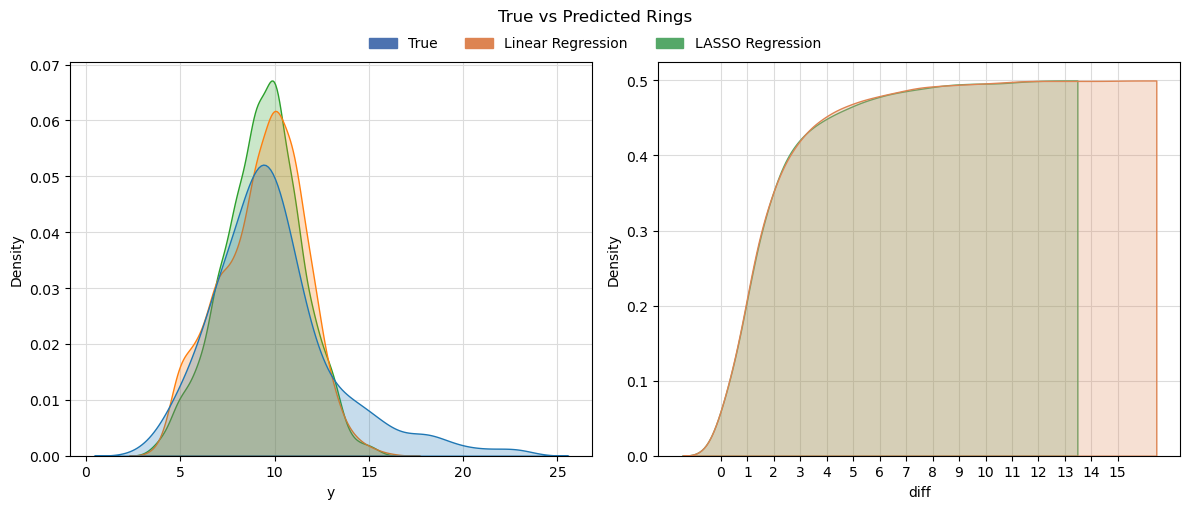

In [ ]:
ys = pd.DataFrame(np.vstack([y_test,y_lr,y_lasso]),index=['true','lr','lasso']).T
ys = ys.melt(var_name='type',value_name='y')

diffs = pd.DataFrame(np.vstack([y_test-y_lr,y_test-y_lasso]),index=['lr','lasso']).T
diffs = diffs.melt(var_name='type',value_name='diff')
diffs['diff'] = abs(diffs['diff'])

fig = plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.grid(color='gainsboro',zorder=1)
sns.kdeplot(ys,x='y',hue='type',fill=True,legend=False,zorder=2)

plt.subplot(1,2,2)
plt.grid(color='gainsboro',zorder=1)
sns.kdeplot(diffs,x='diff',hue='type',fill=True,legend=False,zorder=2,cumulative=True,palette=[sns.color_palette('deep')[1],sns.color_palette('deep')[2]])
plt.xticks([i for i in range(16)])

handles = [
    patches.Patch(color=sns.color_palette('deep')[0],label='True'),
    patches.Patch(color=sns.color_palette('deep')[1],label='Linear Regression'),
    patches.Patch(color=sns.color_palette('deep')[2],label='LASSO Regression')
]
fig.legend(loc='upper center',frameon=False,ncols=3,handles=handles,bbox_to_anchor=(0.5,0.98))
plt.suptitle('True vs Predicted Rings',y=1.01)
plt.tight_layout()
plt.show()

# **Visualization**

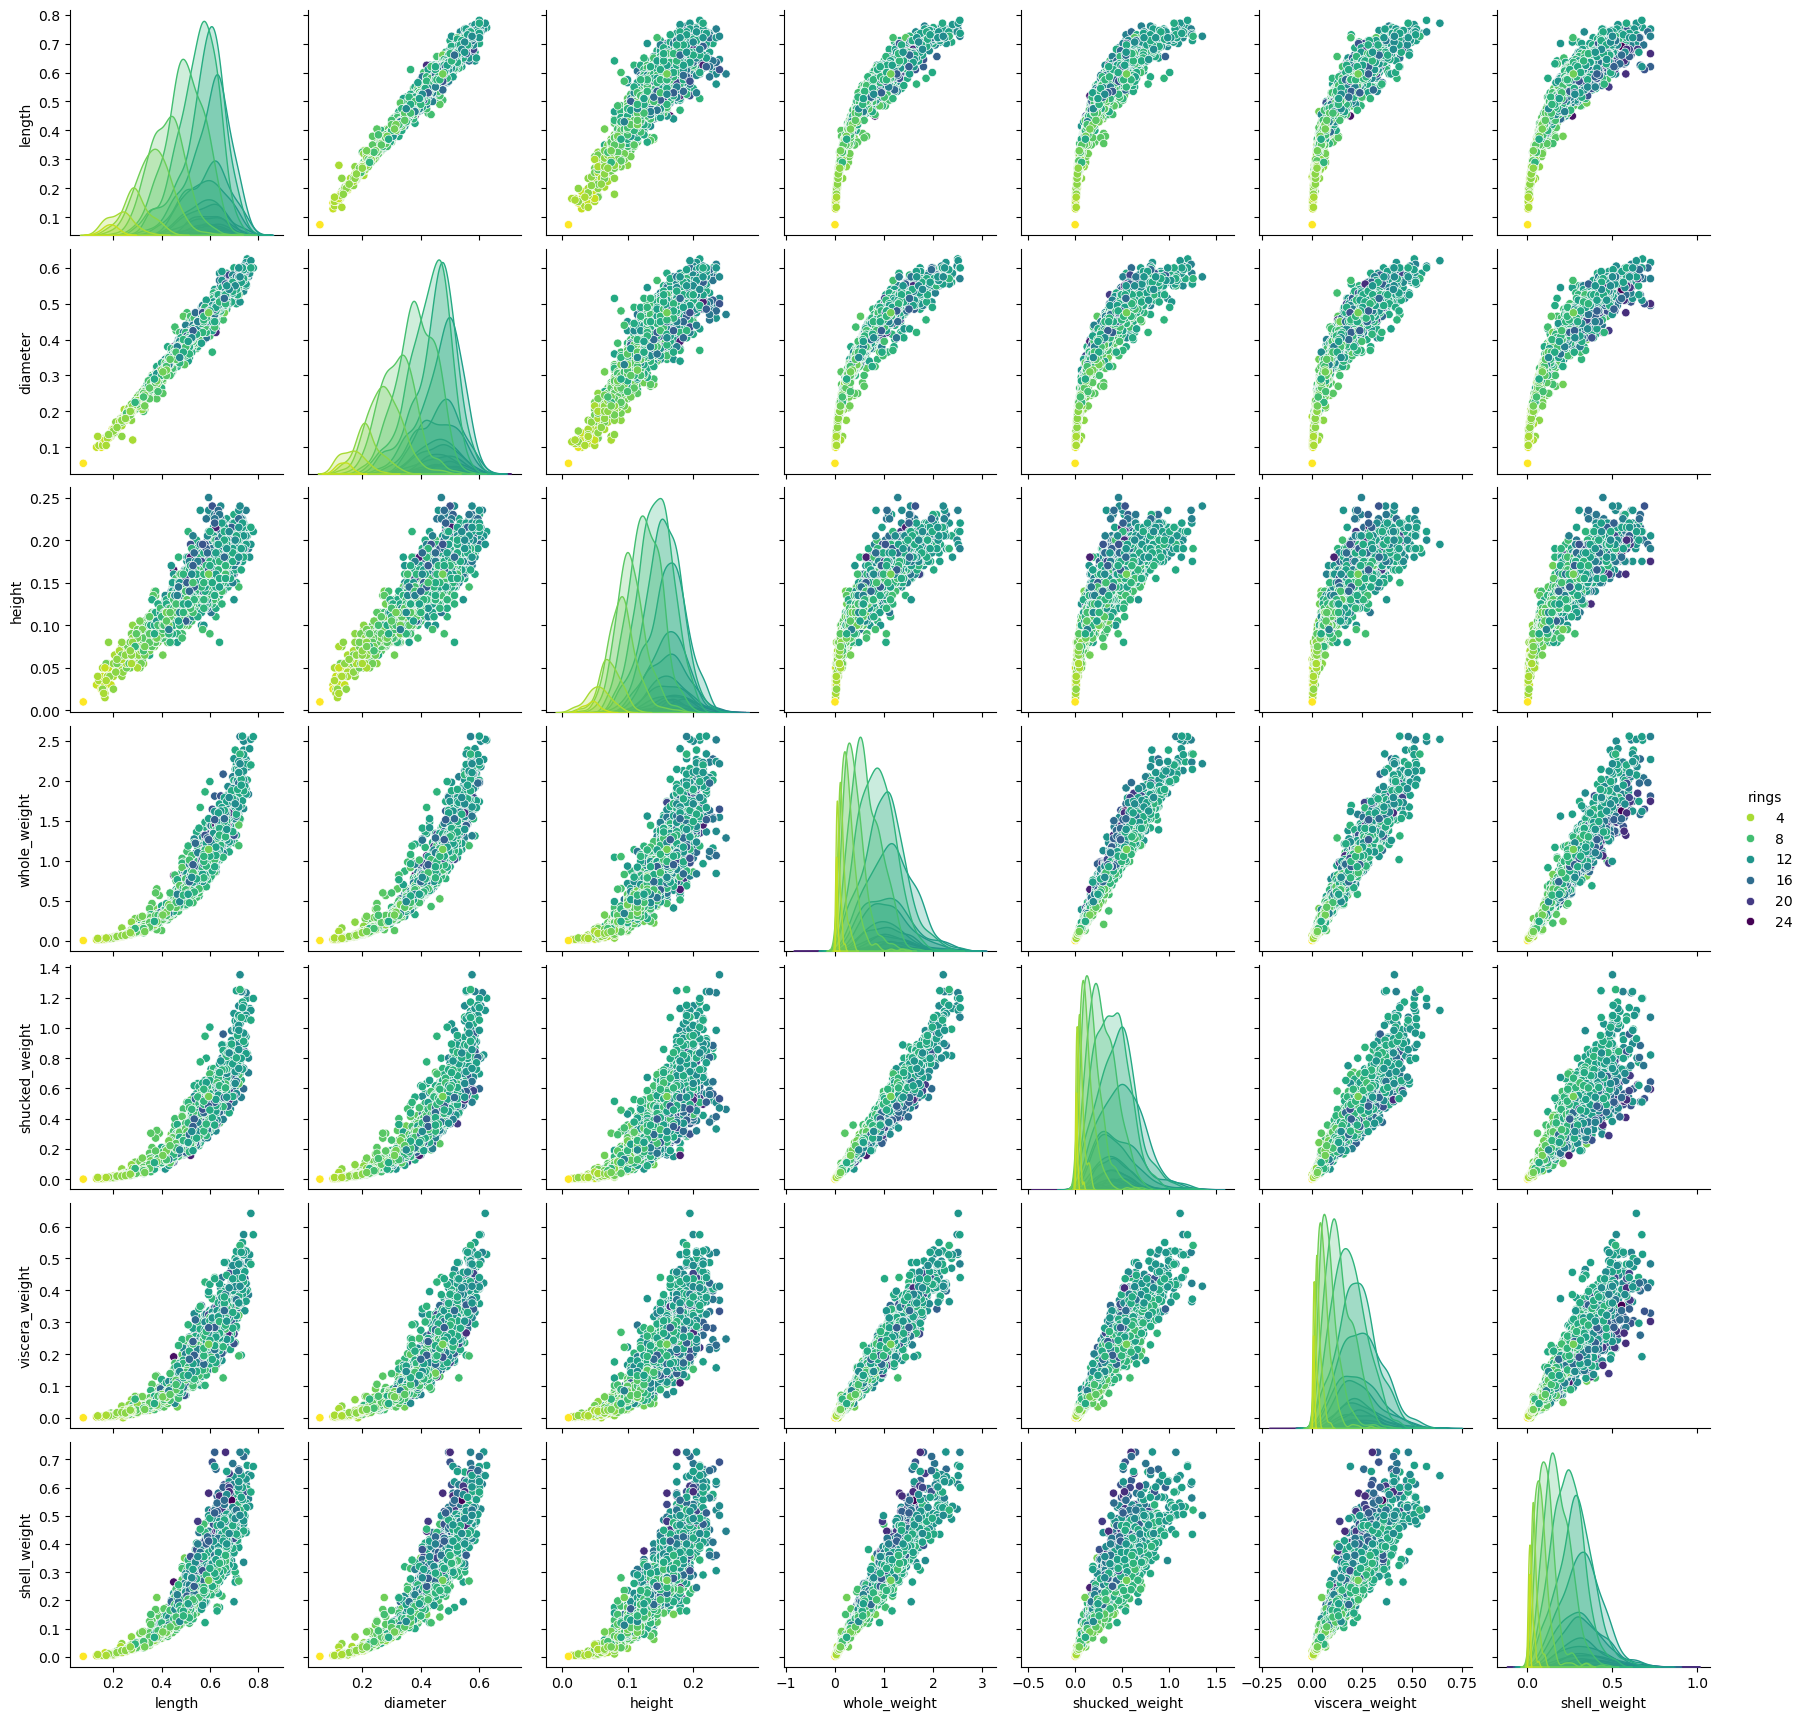

In [ ]:
sns.pairplot(df_train_out,hue='rings',palette='viridis_r')
plt.show()

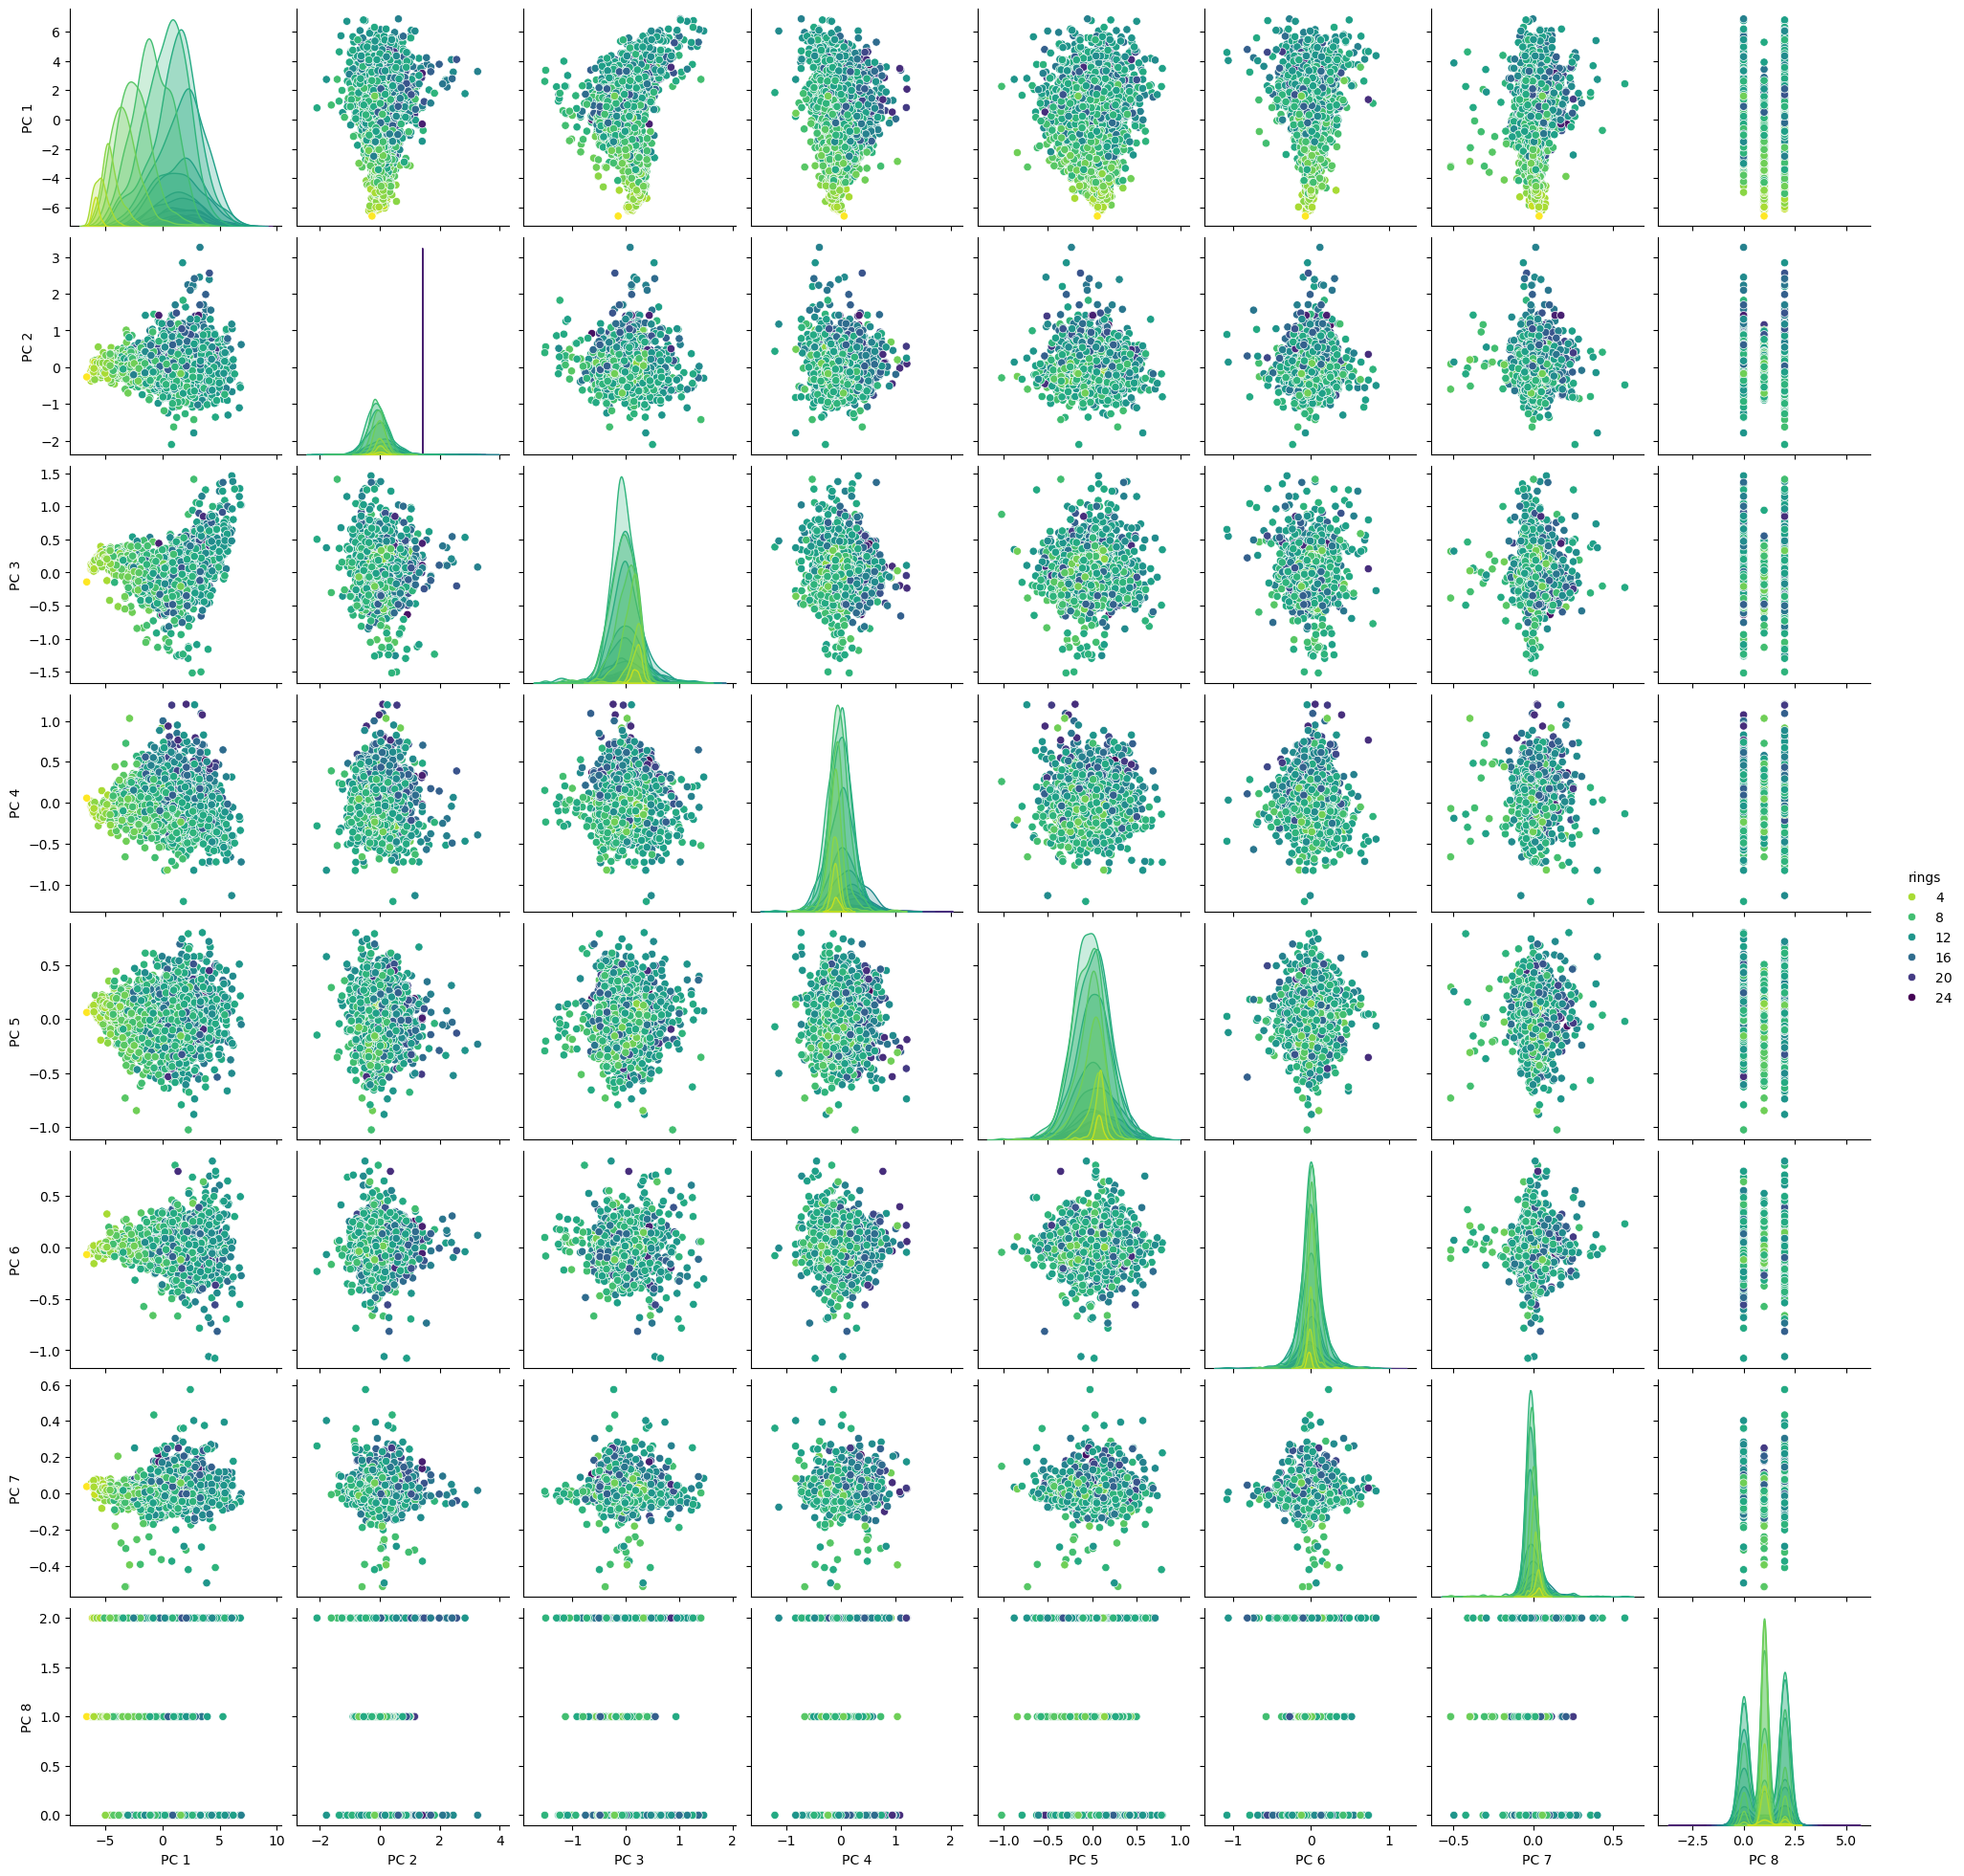

In [ ]:
_vis_df = X_train.copy()
_ct = deepcopy(pl_lr)[:-1]

_vis_df = _ct.transform(_vis_df)
_vis_df = pd.DataFrame(_vis_df,columns=[f'PC {i+1}' for i in range(_vis_df.shape[1])])
_vis_df['rings'] = y_train

sns.pairplot(_vis_df,hue='rings',palette='viridis_r')
plt.show()